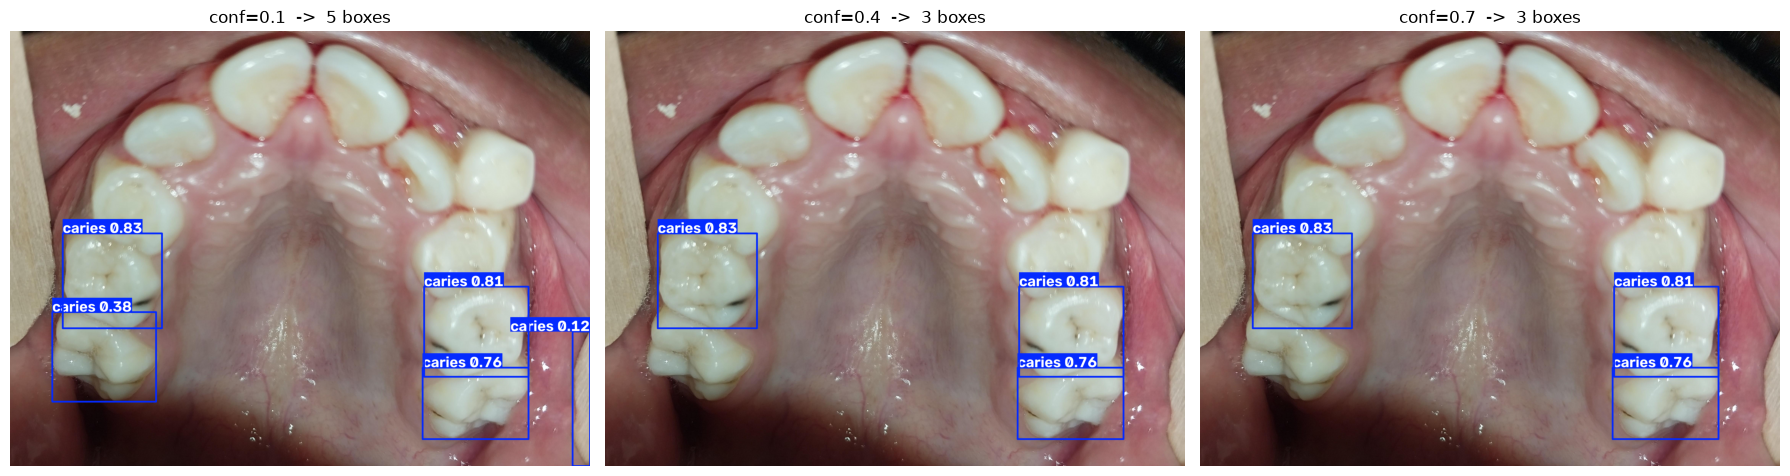

In [2]:
# Watch the threshold change the output

from ultralytics import YOLO
from pathlib import Path
import matplotlib.pyplot as plt

model = YOLO("../data/yolo/models/best.pt")
test_imgs = sorted(Path("../data/yolo/test/images").iterdir())
img = test_imgs[5]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, c in zip(axes, [0.1, 0.4, 0.7]):
    r = model.predict(img, conf=c, device="cpu", verbose=False)[0]
    ax.imshow(r.plot()[..., ::-1])          # r.plot() returns BGR, so flip it to RGB (the Practical 1 trap again)
    ax.set_title(f"conf={c}  ->  {len(r.boxes)} boxes"); ax.axis("off")
plt.tight_layout(); plt.show()

anonymous_003-007-1097-01_1732258152530_Maxillary_Occlusal_View.jpg: 2 suspected lesion(s)  [0.88, 0.87]


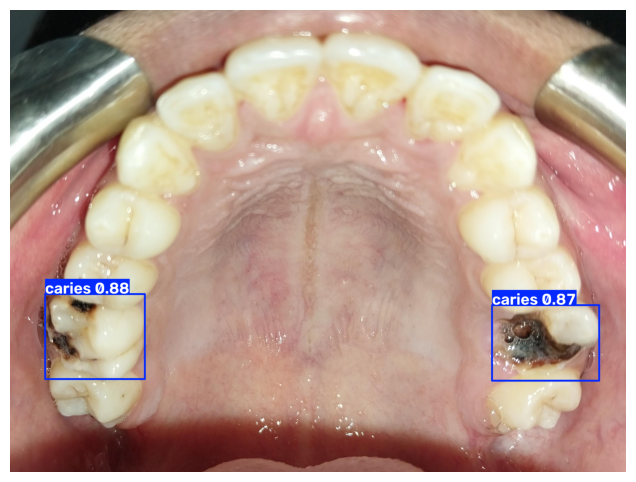

ultralytics.engine.results.Results object with attributes:

boxes: ultralytics.engine.results.Boxes object
depth: None
keypoints: None
masks: None
names: {0: 'caries'}
obb: None
orig_img: array([[[ 60,  58,  47],
        [ 60,  58,  47],
        [ 60,  58,  47],
        ...,
        [ 20,  20,  14],
        [ 19,  19,  13],
        [ 18,  18,  12]],

       [[ 60,  58,  47],
        [ 60,  58,  47],
        [ 60,  58,  47],
        ...,
        [ 22,  22,  16],
        [ 22,  22,  16],
        [ 20,  20,  14]],

       [[ 61,  59,  48],
        [ 61,  59,  48],
        [ 61,  59,  48],
        ...,
        [ 18,  18,  12],
        [ 19,  19,  13],
        [ 18,  18,  12]],

       ...,

       [[ 54,  58, 117],
        [ 54,  58, 117],
        [ 55,  59, 118],
        ...,
        [152, 161, 211],
        [152, 161, 211],
        [152, 161, 211]],

       [[ 53,  57, 116],
        [ 54,  58, 117],
        [ 54,  58, 117],
        ...,
        [152, 161, 211],
        [152, 161, 211],
 

In [5]:
# Wrap it as a small screening function

CONF = 0.4 

def screen(image_path, conf=CONF):
    r = model.predict(image_path, conf=conf, device="cpu", verbose=False)[0]
    scores = [round(float(s), 2) for s in r.boxes.conf]
    print(f"{Path(image_path).name}: {len(scores)} suspected lesion(s)  {scores}")
    plt.figure(figsize=(8, 6)); plt.imshow(r.plot()[..., ::-1]); plt.axis("off"); plt.show()
    return r

screen(test_imgs[10])